# EXP1: Model characteristics

雅克比消融、粒子密度与噪声鲁棒性，以及散度正则参数扫描。


In [1]:
import hashlib
import importlib
import json
import random
import sys
import time
from copy import deepcopy
from dataclasses import asdict, replace
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm.notebook import tqdm


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "generator").is_dir() and (path / "methods").is_dir():
            return path
    raise RuntimeError("Cannot find project root. Please run this notebook inside the project directory.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from methods.affinegs.cmax import ContrastMaximizationLoss
from methods.affinegs.gaussian_flow.model import GaussianVelocityField_Tiled
from methods.affinegs.gaussian_flow.utils import divergence_regularizer
import methods.affinegs.gaussian_flow.config as gf_config
import methods.affinegs.gaussian_flow.training as gf_training
from utils.add_noise import add_event_noise
from utils.metrics import AEE, RMSE, PIVmetric
from utils.painter import extract_data, plot_curvegraph, plot_module_validity

GaussianFlowConfig = gf_config.GaussianFlowConfig
run_gaussian_flow = gf_training.run_gaussian_flow
train_gaussian_flow = gf_training.train_gaussian_flow
render_gaussian_flow = gf_training.render_gaussian_flow

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

CMax fused extension: OK
Using device: cuda
cuda


In [2]:
OUTPUT_DIR = PROJECT_ROOT / "output" / "EXP1"
DEFAULT_PLOT_SIZE = [10, 10, 12]
DEFAULT_USE_CHINESE = False
JACOBIAN_X_MAJOR_TICKS = list(range(100, 501, 100))
JACOBIAN_X_MINOR_TICKS = list(range(50, 501, 50))


def save_results_to_json(results, save_path, indent=1):
    def convert_numpy_types(obj):
        if isinstance(obj, (np.integer, np.floating)):
            return obj.item()
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return obj

    try:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        with open(save_path, "w", encoding="utf-8") as f:
            json.dump(results, f, ensure_ascii=False, indent=indent, default=convert_numpy_types)
        print(f"Results saved to: {save_path}")
    except Exception as e:
        print(f"Save failed: {e}")


def load_results_json(filename):
    with open(OUTPUT_DIR / filename, "r", encoding="utf-8") as f:
        return json.load(f)


def trimmed_mean(values, trim=1, digits=4):
    values = np.sort(np.asarray(values, dtype=float))
    if trim > 0 and values.size > 2 * trim:
        values = values[trim:-trim]
    return round(float(np.mean(values)), digits)


def set_all_seeds(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)


def reload_gaussian_flow_modules():
    global GaussianFlowConfig, run_gaussian_flow, train_gaussian_flow, render_gaussian_flow
    importlib.reload(gf_config)
    importlib.reload(gf_training)
    GaussianFlowConfig = gf_config.GaussianFlowConfig
    run_gaussian_flow = gf_training.run_gaussian_flow
    train_gaussian_flow = gf_training.train_gaussian_flow
    render_gaussian_flow = gf_training.render_gaussian_flow


def make_simulated_event_data(flow_index, *, time_length, d, density, t_min=0, t_max=3):
    cfg_evts = config_events()
    cfg_evts.time_length = time_length
    cfg_evts.d = d
    cfg_evts.density = density

    event_loader = EventManager(
        source_type="simulator",
        path=None,
        cfg=cfg_evts,
        flow_func=flow_funcs[flow_index].evaluate,
    )
    evts, (u, v) = event_loader.load()
    events = evts[(evts[:, 2] > t_min) & (evts[:, 2] < t_max)]
    return events, u.cpu().numpy(), v.cpu().numpy()


def metric_axis_config(y_data_list, tick_step=0.2):
    vals = np.concatenate([np.asarray(y, dtype=float) for y in y_data_list])
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return None, None

    y_max = float(vals.max())
    upper = np.ceil((y_max + 1e-9) / tick_step) * tick_step
    upper = max(tick_step, upper)
    if upper - y_max < 0.05 * tick_step:
        upper += tick_step
    upper = round(float(upper), 2)
    ticks = list(np.round(np.arange(0, upper + 0.5 * tick_step, tick_step), 2))
    return (0, upper), ticks


def plot_metric_pair(
    x_data,
    y_rmse_list,
    y_aee_list,
    *,
    prefix,
    xlabel_en,
    xlabel_zh,
    xlim,
    x_major_ticks,
    x_minor_ticks,
    rmse_ylim=None,
    aee_ylim=None,
    rmse_y_major_ticks=None,
    aee_y_major_ticks=None,
    save=True,
):
    paths = {
        "rmse": str(OUTPUT_DIR / f"{prefix}-rmse.pdf") if save else None,
        "aee": str(OUTPUT_DIR / f"{prefix}-aee.pdf") if save else None,
    }

    for metric, y_data_list, ylim, y_major_ticks in [
        ("RMSE", y_rmse_list, rmse_ylim, rmse_y_major_ticks),
        ("AEE", y_aee_list, aee_ylim, aee_y_major_ticks),
    ]:
        plot_curvegraph(
            x_data=x_data,
            y_data_list=y_data_list,
            legend_names_en=flow_names,
            legend_names_zh=None,
            title_en=None,
            title_zh=None,
            xlabel_en=xlabel_en,
            xlabel_zh=xlabel_zh,
            ylabel_en=f"{metric} $[px/ms]$",
            ylabel_zh=f"{metric} $[px/ms]$",
            ticks_size=DEFAULT_PLOT_SIZE[0],
            legend_size=DEFAULT_PLOT_SIZE[1],
            label_size=DEFAULT_PLOT_SIZE[2],
            xlim=xlim,
            ylim=ylim,
            x_major_ticks=x_major_ticks,
            x_minor_ticks=x_minor_ticks,
            y_major_ticks=y_major_ticks,
            y_minor_ticks=None,
            x_log=False,
            filename=paths[metric.lower()],
            use_chinese=DEFAULT_USE_CHINESE,
        )


def plot_jacobian_ablation(data_filename, output_prefix, x_label, save=True):
    data = load_results_json(data_filename)
    for metric in ["rmse", "aee"]:
        save_path = str(OUTPUT_DIR / f"{output_prefix}-{metric}.pdf") if save else None
        plot_module_validity(
            data,
            flow_names=flow_names,
            metric=metric,
            save_path=save_path,
            x_label=x_label,
            style_names={"1": "AffineGS", "0": "ConstGS"},
            style_linestyles={"1": "-", "0": "--"},
            style_legend_anchor=(0.58, 1.02),
            figsize=(5, 3),
            xlim=(40, 510),
            x_major_ticks=JACOBIAN_X_MAJOR_TICKS,
            x_minor_ticks=JACOBIAN_X_MINOR_TICKS,
            ticks_size=10,
            legend_size=10,
            label_size=12,
            legend_mode="combined",
            combined_legend_loc="upper right",
            combined_legend_anchor=(1.0, 1.02),
            combined_legend_ncol=1,
            combined_legend_label_mode="method_case",
        )


def extract_div_ratio_sweep(data, metric):
    x_vals = None
    y_list = []
    for flow_name in flow_names:
        ratios = np.array(sorted(float(k) for k in data[flow_name].keys()), dtype=float)
        values = np.array([data[flow_name][f"{r:.2f}"][metric] for r in ratios], dtype=float)
        if x_vals is None:
            x_vals = ratios
        y_list.append(values)
    return x_vals, y_list


In [3]:
FLOW_DATA_PATHS = [
    PROJECT_ROOT / "data" / "datasets" / "JHTDB_isotropic1024_hd_00001_flow.npz",
    PROJECT_ROOT / "data" / "datasets" / "DNS_turbulence_00001_flow.npz",
    PROJECT_ROOT / "data" / "datasets" / "SQG_00001_flow.npz",
]
flow_names = ["JHTDB-isotropic", "DNS-turbulence", "SQG"]
flow_funcs = [FlowManager(mode="data", data_path=str(path)) for path in FLOW_DATA_PATHS]
flow0, flow1, flow2 = flow_funcs


## Module validity verification

- Same Gaussian quantity

In [ ]:
jacobian_results = {}
jacobian_init_ns = list(range(50, 510, 50))
jacobian_repeats = 10
jacobian_configs = [
    (enable_jacobian, init_n)
    for enable_jacobian in [1, 0]
    for init_n in jacobian_init_ns
]

for flow_index in tqdm(range(3), desc="Flows", position=0):
    flow_key = f"flow{flow_index}"
    jacobian_results[flow_key] = {}
    events, h_gt, w_gt = make_simulated_event_data(flow_index, time_length=5, d=0.5, density=0.05)

    for enable_jacobian, init_n in tqdm(jacobian_configs, desc=flow_key, leave=False, position=1):
        jac_key = str(enable_jacobian)
        jacobian_results[flow_key].setdefault(jac_key, {})
        rmse_list, aee_list = [], []

        for _ in tqdm(range(jacobian_repeats), desc="repeat", leave=False, position=2):
            cfg = GaussianFlowConfig(
                verbose=False,
                init_n=init_n,
                enable_jacobian=enable_jacobian,
                phase=[500, 200, 250],
                iterations=300,
                lr_j=0.001,
            )
            res = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            pred_h, pred_w = res.flow[0], res.flow[1]
            rmse, aee = PIVmetric(pred_h, pred_w, h_gt, w_gt, show=False)[:2]
            rmse_list.append(rmse)
            aee_list.append(aee)

        jacobian_results[flow_key][jac_key][str(init_n)] = {
            "rmse": trimmed_mean(rmse_list),
            "aee": trimmed_mean(aee_list),
        }

save_results_to_json(jacobian_results, OUTPUT_DIR / "1-jacobian-results.json", indent=1)


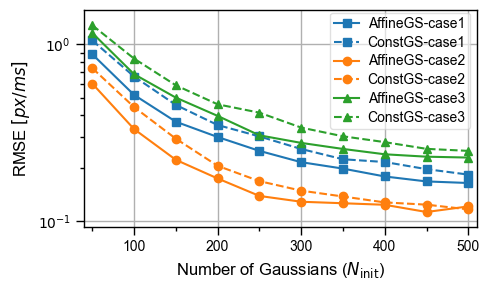

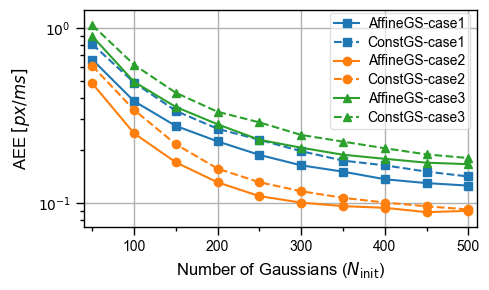

In [ ]:
save_jacobian_figures = True

plot_jacobian_ablation(
    data_filename="1-jacobian-results.json",
    output_prefix="1-jacobian",
    x_label=r"Number of Gaussians ($N_{\mathrm{init}}$)",
    save=save_jacobian_figures,
)


- Same Gaussian quantity with frozen geometry


In [ ]:
def clone_shared_geometry_model(base_model, enable_jacobian, cfg):
    """Create a model with exactly the same Gaussian geometry as base_model."""
    model = GaussianVelocityField_Tiled(
        num_gaussians=base_model.num_gaussians,
        H=base_model.H,
        W=base_model.W,
        tile_size=base_model.tile_size,
        enable_jacobian=enable_jacobian,
        device=base_model.mu.device,
        jacobian_mode=cfg.jacobian_mode,
        init_scale_h=cfg.init_scale_h,
        init_scale_w=cfg.init_scale_w,
    ).to(base_model.mu.device)

    with torch.no_grad():
        model.mu.copy_(base_model.mu)
        model.log_scale.copy_(base_model.log_scale)
        model.rotation.copy_(base_model.rotation)
        model.opacity_logit.copy_(base_model.opacity_logit)
        model.local_velocity.copy_(base_model.local_velocity)
        if model.J_params is not None:
            model.J_params.zero_()

    # Freeze only the Gaussian support. The ablation tests the velocity model on identical geometry.
    for param in (model.mu, model.log_scale, model.rotation, model.opacity_logit):
        param.requires_grad_(False)

    model.rebuild_indexer()
    return model


def train_frozen_geometry_model(model, events, cfg, iterations):
    model.train()
    events = events.to(model.mu.device)

    param_groups = [{"params": [model.local_velocity], "lr": 0.05, "name": "velocity"}]
    if model.J_params is not None:
        lr_j = cfg.lr_j if cfg.lr_j is not None else 0.001
        param_groups.append({"params": [model.J_params], "lr": lr_j, "name": "jacobian"})

    optimizer = torch.optim.Adam(param_groups, betas=(0.9, 0.999), eps=1e-15)
    cmax_loss_fn = ContrastMaximizationLoss(
        loss_type=cfg.cmax_loss_type,
        sigma=cfg.cmax_sigma,
        kernel_size=cfg.cmax_kernel_size,
    ).to(model.mu.device)

    for i in range(iterations):
        optimizer.zero_grad(set_to_none=True)
        pred_flow, _, _, _ = model(rebuild_index=(i == 0), compute_derivatives=False)
        loss_data = cmax_loss_fn(events, pred_flow, (cfg.H, cfg.W))
        div_loss = divergence_regularizer(pred_flow, top_ratio=cfg.div_top_ratio)
        weight_div = cfg.w_div if i < cfg.div_last else 0.0
        loss = loss_data + weight_div * div_loss
        loss.backward()
        optimizer.step()

    return model


frozen_geometry_results = {}
frozen_init_ns = list(range(50, 510, 50))
frozen_repeats = 10
frozen_pretrain_iterations = 300
frozen_refine_iterations = 150

for flow_index in tqdm(range(3), desc="Flows", position=0):
    flow_key = f"flow{flow_index}"
    frozen_geometry_results[flow_key] = {"1": {}, "0": {}}
    events, h_gt, w_gt = make_simulated_event_data(flow_index, time_length=5, d=0.5, density=0.05)

    for init_n in tqdm(frozen_init_ns, desc=flow_key, leave=False, position=1):
        metric_cache = {
            "1": {"rmse": [], "aee": []},
            "0": {"rmse": [], "aee": []},
        }

        for _ in tqdm(range(frozen_repeats), desc="repeat", leave=False, position=2):
            base_cfg = GaussianFlowConfig(
                verbose=False,
                init_n=init_n,
                enable_jacobian=False,
                phase=[10**9, 10**9, 10**9],
                iterations=frozen_pretrain_iterations,
                lr_j=0.001,
            )
            base_model, _ = train_gaussian_flow(events=events, cfg=base_cfg, flowgt=None)

            for jac_key, enable_jacobian in [("1", True), ("0", False)]:
                refine_cfg = GaussianFlowConfig(
                    verbose=False,
                    init_n=init_n,
                    enable_jacobian=enable_jacobian,
                    phase=[10**9, 10**9, 10**9],
                    iterations=frozen_refine_iterations,
                    lr_j=0.001,
                )
                model = clone_shared_geometry_model(base_model, enable_jacobian, refine_cfg)
                model = train_frozen_geometry_model(model, events, refine_cfg, frozen_refine_iterations)
                res = render_gaussian_flow(model, verbose=False)

                pred_h, pred_w = res.flow[0], res.flow[1]
                rmse, aee = PIVmetric(pred_h, pred_w, h_gt, w_gt, show=False)[:2]
                metric_cache[jac_key]["rmse"].append(rmse)
                metric_cache[jac_key]["aee"].append(aee)

                del model, res
                torch.cuda.empty_cache()

            del base_model
            torch.cuda.empty_cache()

        for jac_key in ["1", "0"]:
            frozen_geometry_results[flow_key][jac_key][str(init_n)] = {
                "rmse": trimmed_mean(metric_cache[jac_key]["rmse"]),
                "aee": trimmed_mean(metric_cache[jac_key]["aee"]),
                "init_n": int(init_n),
                "frozen_geometry": True,
                "pretrain_iterations": int(frozen_pretrain_iterations),
                "refine_iterations": int(frozen_refine_iterations),
                "repeats": int(frozen_repeats),
            }

save_results_to_json(frozen_geometry_results, OUTPUT_DIR / "2-jacobian-frozen-geometry-results.json", indent=1)


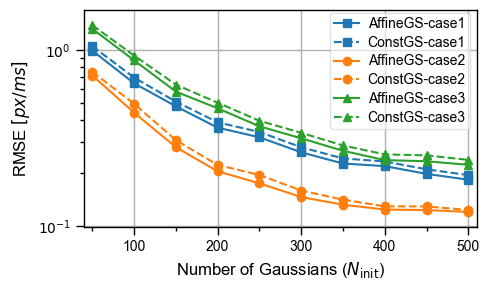

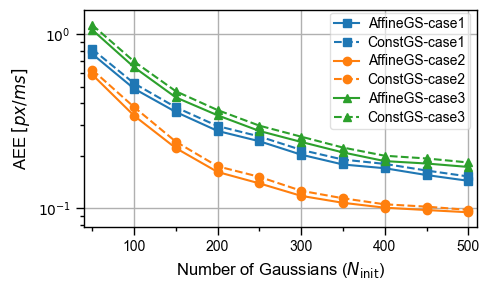

In [ ]:
save_frozen_geometry_figures = True

plot_jacobian_ablation(
    data_filename="2-jacobian-frozen-geometry-results.json",
    output_prefix="2-jacobian-frozen-geometry",
    x_label=r"Number of Gaussians ($N_{\mathrm{init}}$)",
    save=save_frozen_geometry_figures,
)


## Robustness investigation

- particle density

In [ ]:
density_results = {}
density_values = np.round(np.arange(0.01, 0.1001, 0.01), 2)
density_repeats = 10

for flow_index in tqdm(range(3), desc="flows"):
    single_flow_results = {}

    for density in tqdm(density_values, desc=f"{flow_names[flow_index]}-Density", leave=False):
        rmse_list, aee_list = [], []

        for _ in range(density_repeats):
            events, u_gt, v_gt = make_simulated_event_data(
                flow_index,
                time_length=4,
                d=0.05,
                density=float(density),
            )
            cfg = GaussianFlowConfig(lr_j=0.001)
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)

            pred_h, pred_w = result.flow[0], result.flow[1]
            rmse, aee = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)[:2]
            rmse_list.append(rmse)
            aee_list.append(aee)

        single_flow_results[f"{density:.6f}"] = {
            "rmse": trimmed_mean(rmse_list),
            "aee": trimmed_mean(aee_list),
        }

    density_results[flow_names[flow_index]] = single_flow_results

save_results_to_json(density_results, OUTPUT_DIR / "3-density-results.json", indent=1)


In [ ]:
save_density_figures = True

density_data = load_results_json("3-density-results.json")
x_vals, y_rmse_list, y_aee_list = extract_data(density_data)

rmse_ylim, rmse_y_major_ticks = metric_axis_config(y_rmse_list, tick_step=0.2)
aee_ylim, aee_y_major_ticks = metric_axis_config(y_aee_list, tick_step=0.2)
density_sample_ticks = list(np.round(np.arange(0.01, 0.1001, 0.01), 2))

plot_metric_pair(
    x_data=x_vals,
    y_rmse_list=y_rmse_list,
    y_aee_list=y_aee_list,
    prefix="3-density",
    xlabel_en="Particle density $\rho_{p}$ $[ppp]$",
    xlabel_zh="粒子密度 $\rho_{p}$",
    xlim=(0.008, 0.102),
    x_major_ticks=list(np.round(np.arange(0.01, 0.1001, 0.02), 2)),
    x_minor_ticks=density_sample_ticks,
    rmse_ylim=rmse_ylim,
    aee_ylim=aee_ylim,
    rmse_y_major_ticks=rmse_y_major_ticks,
    aee_y_major_ticks=aee_y_major_ticks,
    save=save_density_figures,
)


- noise ratio

背景、热像素、突发噪声保持原来的 50%/25%/25% 分配。噪声比例定义为**已有事件中被修改的比例**：
从 N 条事件中无放回选取 `round(N * noise_ratio)` 条并替换其坐标、时间或极性，输出事件总数仍为 N，不再追加噪声事件。
默认散度正则权重由公共 `GaussianFlowConfig` 提供，当前为 15。

修改噪声模型后，需重跑下方噪声实验生成新结果；此前保存的噪声结果不代表当前设置。


In [ ]:
# 更新已打开内核中的公共默认配置和噪声函数，避免沿用旧的追加事件实现。
reload_gaussian_flow_modules()
event_noise_module = importlib.import_module("utils.add_noise")
importlib.reload(event_noise_module)
add_event_noise = event_noise_module.add_event_noise

noise_results = {}
noise_ratios = np.arange(0, 0.21, 0.02)
noise_repeats = 10

for flow_index in tqdm(range(3), desc="flows"):
    events, u_gt, v_gt = make_simulated_event_data(flow_index, time_length=5, d=0.5, density=0.05)
    single_flow_results = {}

    for noise_ratio in tqdm(noise_ratios, desc="Noise ratio", leave=False):
        rmse_list, aee_list = [], []

        for _ in range(noise_repeats):
            # 噪声预算不变；修改已有事件，保持事件总数不变。
            noisy_events = add_event_noise(events, 256, 256, noise_ratio=float(noise_ratio))
            assert len(noisy_events) == len(events), "噪声注入不能改变事件总数"
            cfg = GaussianFlowConfig()
            res = run_gaussian_flow(events=noisy_events, cfg=cfg, flowgt=None)

            pred_h, pred_w = res.flow[:2]
            rmse, aee = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)[:2]
            rmse_list.append(float(rmse))
            aee_list.append(float(aee))

        single_flow_results[f"{noise_ratio:.2f}"] = {
            "rmse": trimmed_mean(rmse_list),
            "aee": trimmed_mean(aee_list),
        }

    noise_results[flow_names[flow_index]] = single_flow_results

save_results_to_json(noise_results, OUTPUT_DIR / "4-noise-results.json", indent=1)


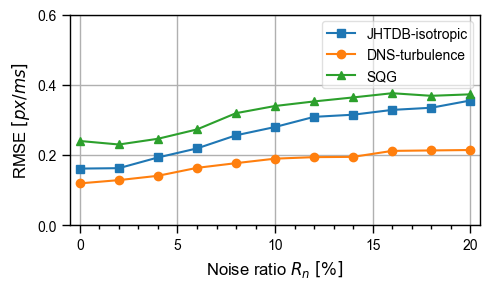

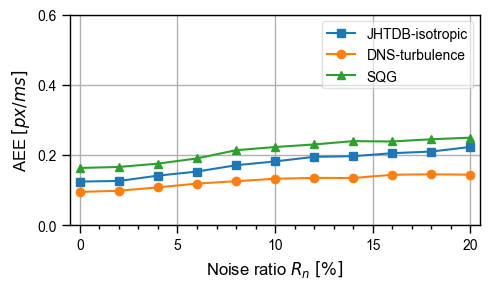

In [4]:
save_noise_figures = True

noise_data = load_results_json("4-noise-results.json")
x_vals, y_rmse_list, y_aee_list = extract_data(noise_data)

plot_metric_pair(
    x_data=x_vals * 100,
    y_rmse_list=y_rmse_list,
    y_aee_list=y_aee_list,
    prefix="4-noise",
    xlabel_en="Noise ratio $R_n$ $[\%]$",
    xlabel_zh="噪声比例 $R_n$ $[\%]$",
    xlim=(-0.5, 20.5),
    x_major_ticks=list(range(0, 21, 5)),
    x_minor_ticks=list(range(1, 21, 1)),
    rmse_ylim=(0, 0.6),
    aee_ylim=(0, 0.6),
    rmse_y_major_ticks=[0, 0.2, 0.4, 0.6],
    aee_y_major_ticks=[0, 0.2, 0.4, 0.6],
    save=save_noise_figures,
)


## Divergence top-ratio sweep

扫描 $R_d=0,0.05,\ldots,0.5$；每个流场重复 10 次，各比例共享事件和初始化种子。


In [4]:
reload_gaussian_flow_modules()

div_ratio_sweep_results = {}
div_top_ratios = np.round(np.arange(0.0, 0.5001, 0.05), 2)
num_repeats_ratio = 10
ratio_base_seed = 2026

for flow_index in tqdm(range(3), desc="Flows"):
    flow_name = flow_names[flow_index]
    div_ratio_sweep_results[flow_name] = {}

    set_all_seeds(ratio_base_seed + flow_index)
    events, u_gt, v_gt = make_simulated_event_data(flow_index, time_length=5, d=0.5, density=0.05)

    for ratio in tqdm(div_top_ratios, desc=f"{flow_name} ratios", leave=False):
        rmse_list, aee_list = [], []

        for repeat_index in range(num_repeats_ratio):
            # Paired seed across ratios: only div_top_ratio changes.
            run_seed = ratio_base_seed + flow_index * 100 + repeat_index
            set_all_seeds(run_seed)

            cfg = GaussianFlowConfig(
                div_top_ratio=float(ratio),
                lr_j=0.001,
                verbose=False,
            )
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            pred_h, pred_w = result.flow[:2]
            rmse, aee = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)[:2]
            rmse_list.append(float(rmse))
            aee_list.append(float(aee))

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        div_ratio_sweep_results[flow_name][f"{ratio:.2f}"] = {
            "rmse": round(float(np.mean(rmse_list)), 4),
            "aee": round(float(np.mean(aee_list)), 4),
            "std_rmse": round(float(np.std(rmse_list)), 4),
            "std_aee": round(float(np.std(aee_list)), 4),
            "num_repeats": int(num_repeats_ratio),
        }

save_results_to_json(div_ratio_sweep_results, OUTPUT_DIR / "5-div-top-ratio-sweep-results.json", indent=1)


Flows:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB-isotropic ratios:   0%|          | 0/11 [00:00<?, ?it/s]

DNS-turbulence ratios:   0%|          | 0/11 [00:00<?, ?it/s]

SQG ratios:   0%|          | 0/11 [00:00<?, ?it/s]

Results saved to: /media/newdisk/junjie/2dGS-representation/output/EXP1/5-div-top-ratio-sweep-results.json


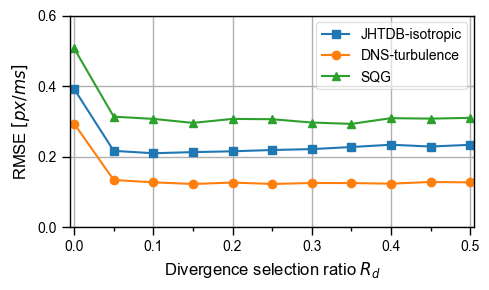

In [5]:
# Read saved results and export only RMSE; no training is needed.
div_ratio_sweep_data = load_results_json("5-div-top-ratio-sweep-results.json")
x_vals, y_rmse_list = extract_div_ratio_sweep(div_ratio_sweep_data, "rmse")

plot_curvegraph(
    x_data=x_vals,
    y_data_list=y_rmse_list,
    legend_names_en=flow_names,
    legend_names_zh=flow_names,
    title_en=None, title_zh=None,
    xlabel_en=r"Divergence selection ratio $R_d$",
    xlabel_zh=r"最大散度比例 $R_d$",
    ylabel_en=r"RMSE $[px/ms]$",
    ylabel_zh=r"RMSE $[px/ms]$",
    ticks_size=10, legend_size=10, label_size=12,
    # 与 lambda 图一样，在横轴两端各留出范围的 1%。
    xlim=(-0.005, 0.505),
    x_major_ticks=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5],
    x_minor_ticks=[0.05, 0.15, 0.25, 0.35, 0.45],
    ylim=(0.0, 0.6),
    y_major_ticks=[0.0, 0.2, 0.4, 0.6],
    filename=str(OUTPUT_DIR / "5-div-top-ratio-sweep-rmse.pdf"),
    figsize=(5, 3),
)


## Regularization-weight sweep

固定 $R_d=0.1$，扫描 $\lambda=0,5,\ldots,50$。三个流场各重复 10 次、每次训练 300 步，同一次重复共享事件和初始化。

训练单元从头运行并逐次保存至 `output/EXP1/divergence_weight_sweep/`；最后的绘图单元读取结果，仅导出 RMSE PDF。


In [6]:
from dataclasses import asdict, replace
import random
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow
from utils.metrics import RMSE, AEE
from methods import compute_flow_quantities

W_P10_OUTPUT_DIR = PROJECT_ROOT / "output" / "EXP1" / "divergence_weight_sweep"
W_P10_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
W_P10_RESULT_PATH = W_P10_OUTPUT_DIR / "divergence-weight-p10-results.json"
w_p10_values = list(range(0, 51, 5))
w_p10_repeats = 10
w_p10_base_seed = 2026
w_p10_flow_names = ["JHTDB-isotropic", "DNS-turbulence", "SQG"]
w_p10_flow_paths = [
    PROJECT_ROOT / "data" / "datasets" / "JHTDB_isotropic1024_hd_00001_flow.npz",
    PROJECT_ROOT / "data" / "datasets" / "DNS_turbulence_00001_flow.npz",
    PROJECT_ROOT / "data" / "datasets" / "SQG_00001_flow.npz",
]
w_p10_base_cfg = GaussianFlowConfig(
    H=256, W=256, init_n=300, iterations=300,
    enable_jacobian=True, enable_density_control=True,
    lr_j=0.001, div_top_ratio=0.1, verbose=False,
)
w_p10_event_settings = dict(time_length=4.01, d=0.5, density=0.05,
                            t_min=0.0, t_max=3.0)


def w_p10_set_seed(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)


def w_p10_make_events(flow_source):
    event_cfg = config_events()
    event_cfg.height, event_cfg.width = w_p10_base_cfg.H, w_p10_base_cfg.W
    event_cfg.device = w_p10_base_cfg.device
    for key in ("time_length", "d", "density"):
        event_cfg[key] = w_p10_event_settings[key]
    events, (h_gt, w_gt) = EventManager(
        source_type="simulator", cfg=event_cfg, flow_func=flow_source.evaluate,
    ).load()
    valid = ((events[:, 2] > w_p10_event_settings["t_min"]) &
             (events[:, 2] < w_p10_event_settings["t_max"]))
    events = events[valid]
    if len(events) == 0:
        raise RuntimeError("No simulated events in the selected training window.")
    return events, h_gt.squeeze().detach().cpu().numpy(), w_gt.squeeze().detach().cpu().numpy()


def w_p10_evaluate(result, h_gt, w_gt):
    pred_h, pred_w = result.flow[:2]
    div_pred, vor_pred = compute_flow_quantities(pred_h, pred_w)
    div_gt, vor_gt = compute_flow_quantities(h_gt, w_gt)
    div_pred = div_pred.detach().cpu().numpy()
    div_gt = div_gt.detach().cpu().numpy()
    vor_pred = vor_pred.detach().cpu().numpy()
    vor_gt = vor_gt.detach().cpu().numpy()
    return {
        "rmse": float(RMSE(h_gt, w_gt, pred_h, pred_w)),
        "aee": float(AEE(h_gt, w_gt, pred_h, pred_w)),
        "mean|div|": float(np.mean(np.abs(div_pred))),
        "RMSE_div": float(np.sqrt(np.mean((div_pred - div_gt) ** 2))),
        "RMSE_ω": float(np.sqrt(np.mean((vor_pred - vor_gt) ** 2))),
        "num_gaussians": int(result.model.num_gaussians),
    }


In [7]:
w_p10_metadata = {
    "method": "AffineGS",
    "flow_names": w_p10_flow_names,
    "flow_paths": [str(path.relative_to(PROJECT_ROOT)) for path in w_p10_flow_paths],
    "w_div_values": w_p10_values,
    "div_top_ratio": 0.1,
    "num_repeats": w_p10_repeats,
    "base_seed": w_p10_base_seed,
    "training_config": asdict(w_p10_base_cfg),
    "event_settings": w_p10_event_settings,
    "paired_events_and_initialization": True,
    "derivative_evaluation": "replicate-boundary central differences, unit pixel spacing, full image",
    "std_definition": "population standard deviation (ddof=0)",
}
# Match JSON's normalized representation, including NumPy scalar config values.
w_p10_metadata = json.loads(json.dumps(w_p10_metadata, default=lambda value: value.item()))
# Always start a fresh sweep; do not read or reuse previous results.
w_p10_results = {
    "metadata": w_p10_metadata,
    "flows": {name: {str(weight): [] for weight in w_p10_values}
              for name in w_p10_flow_names},
}

for flow_index, (flow_name, flow_path) in enumerate(
        tqdm(list(zip(w_p10_flow_names, w_p10_flow_paths)), desc="Weight sweep: flows")):
    flow_source = FlowManager(mode="data", data_path=str(flow_path))
    for repeat in tqdm(range(w_p10_repeats), desc=f"{flow_name}: repeats", leave=False):
        event_seed = w_p10_base_seed + 1000 * flow_index + repeat
        train_seed = w_p10_base_seed + 100000 + 1000 * flow_index + repeat
        w_p10_set_seed(event_seed)
        events, h_gt, w_gt = w_p10_make_events(flow_source)
        for weight in tqdm(w_p10_values, desc=f"{flow_name} #{repeat}: weights", leave=False):
            # All settings are identical across weights, including initialization.
            cfg = replace(w_p10_base_cfg, w_div=float(weight))
            w_p10_set_seed(train_seed)
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            metrics = w_p10_evaluate(result, h_gt, w_gt)
            if not all(np.isfinite(value) for value in metrics.values()):
                raise RuntimeError(f"Non-finite metrics: {flow_name}, repeat={repeat}, w={weight}.")
            row = dict(repeat=repeat, w_div=weight, event_seed=event_seed,
                       train_seed=train_seed, event_count=len(events), **metrics)
            w_p10_results["flows"][flow_name][str(weight)].append(row)
            # Atomic checkpoint after every completed run.
            checkpoint_path = W_P10_RESULT_PATH.with_suffix(".json.tmp")
            with checkpoint_path.open("w", encoding="utf-8") as f:
                json.dump(w_p10_results, f, ensure_ascii=False, indent=1, allow_nan=False)
            checkpoint_path.replace(W_P10_RESULT_PATH)
            del result
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        del events, h_gt, w_gt

print(f"Saved: {W_P10_RESULT_PATH}")


Weight sweep: flows:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB-isotropic: repeats:   0%|          | 0/10 [00:00<?, ?it/s]

JHTDB-isotropic #0: weights:   0%|          | 0/11 [00:00<?, ?it/s]

JHTDB-isotropic #1: weights:   0%|          | 0/11 [00:00<?, ?it/s]

JHTDB-isotropic #2: weights:   0%|          | 0/11 [00:00<?, ?it/s]

...

SQG #6: weights:   0%|          | 0/11 [00:00<?, ?it/s]

SQG #7: weights:   0%|          | 0/11 [00:00<?, ?it/s]

SQG #8: weights:   0%|          | 0/11 [00:00<?, ?it/s]

SQG #9: weights:   0%|          | 0/11 [00:00<?, ?it/s]

Saved: /media/newdisk/junjie/2dGS-representation/output/EXP1/divergence_weight_sweep/divergence-weight-p10-results.json


Saved: /media/newdisk/junjie/2dGS-representation/output/EXP1/divergence-weight-p10-results-rmse.pdf
JHTDB-isotropic: best velocity RMSE w=10
DNS-turbulence: best velocity RMSE w=10
SQG: best velocity RMSE w=10


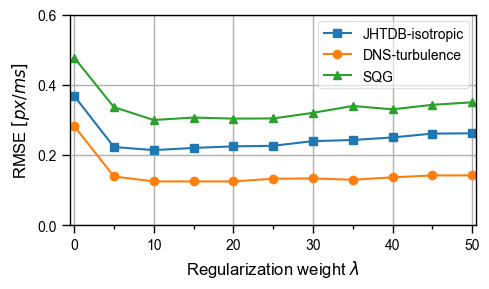

In [ ]:
# All figure-generation code lives in utils/painter.py.
# This cell only reads the saved sweep; it does not run any training.
import importlib
import utils.painter as painter
importlib.reload(painter)

w_p10_summary = painter.plot_divergence_weight_sweep(
    W_P10_RESULT_PATH, output_dir=OUTPUT_DIR, save=True,
    metrics=("rmse",), ylim=(0.0, 0.6),
    y_major_ticks=[0.0, 0.2, 0.4, 0.6],
)
with (W_P10_OUTPUT_DIR / "divergence-weight-p10-summary.json").open("w", encoding="utf-8") as f:
    json.dump(w_p10_summary, f, ensure_ascii=False, indent=1, allow_nan=False)

for name in w_p10_flow_names:
    best_velocity_w = min(w_p10_values, key=lambda w: w_p10_summary[name][str(w)]["rmse"]["mean"])
    print(f"{name}: best velocity RMSE w={best_velocity_w}")


## Paired regularization sweeps

共享事件与初始化扫描 $R_d$ 和 $\lambda$，共 600 次训练。训练单元从头覆盖结果；绘图单元读取已保存数据。


In [ ]:
PAIRED_OUTPUT_DIR = PROJECT_ROOT / "output" / "EXP1" / "paired_regularization"
PAIRED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PAIRED_RESULT_PATH = PAIRED_OUTPUT_DIR / "paired-rd-lambda-results.json"

paired_flow_names = ["JHTDB-isotropic", "DNS-turbulence", "SQG"]
paired_flow_paths = [
    PROJECT_ROOT / "data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz",
    PROJECT_ROOT / "data/datasets/DNS_turbulence_00001_flow.npz",
    PROJECT_ROOT / "data/datasets/SQG_00001_flow.npz",
]
paired_rd_values = np.round(np.arange(0.0, 0.5001, 0.05), 2).tolist()
paired_lambda_values = list(range(0, 51, 5))
paired_repeats = 10
paired_base_seed = 2026
paired_fixed_lambda = 10.0
paired_fixed_rd = 0.1
paired_base_cfg = GaussianFlowConfig(
    H=256, W=256, init_n=300, iterations=300,
    enable_jacobian=True, enable_density_control=True,
    lr_j=0.001, w_div=paired_fixed_lambda, div_top_ratio=paired_fixed_rd,
    verbose=False,
)
paired_event_settings = dict(time_length=4.01, d=0.5, density=0.05,
                      t_min=0.0, t_max=3.0)


def paired_normalize_json(value):
    return json.loads(json.dumps(value, default=lambda item: item.item()))


def paired_set_seed(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)


def paired_file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def paired_tensor_sha256(tensor):
    array = tensor.detach().contiguous().cpu().numpy()
    digest = hashlib.sha256()
    digest.update(str(array.dtype).encode())
    digest.update(str(array.shape).encode())
    digest.update(array.tobytes())
    return digest.hexdigest()


def paired_initial_model_sha256(cfg, train_seed):
    paired_set_seed(train_seed)
    model = GaussianVelocityField_Tiled(
        num_gaussians=cfg.init_n, H=cfg.H, W=cfg.W,
        tile_size=cfg.tile_size, enable_jacobian=cfg.enable_jacobian,
        device=cfg.device, jacobian_mode=cfg.jacobian_mode,
        init_scale_h=cfg.init_scale_h, init_scale_w=cfg.init_scale_w,
    )
    digest = hashlib.sha256()
    for name, value in model.named_parameters():
        digest.update(name.encode())
        digest.update(paired_tensor_sha256(value).encode())
    del model
    return digest.hexdigest()


def paired_make_events(flow_source):
    event_cfg = config_events()
    event_cfg.height, event_cfg.width = paired_base_cfg.H, paired_base_cfg.W
    event_cfg.device = paired_base_cfg.device
    for key in ("time_length", "d", "density"):
        event_cfg[key] = paired_event_settings[key]
    events, (h_gt, w_gt) = EventManager(
        source_type="simulator", cfg=event_cfg,
        flow_func=flow_source.evaluate,
    ).load()
    valid = ((events[:, 2] > paired_event_settings["t_min"]) &
             (events[:, 2] < paired_event_settings["t_max"]))
    events = events[valid]
    if len(events) == 0:
        raise RuntimeError("No simulated events inside the training window.")
    return (events, h_gt.squeeze().detach().cpu().numpy(),
            w_gt.squeeze().detach().cpu().numpy())


def paired_save_results(paired_results):
    temporary = PAIRED_RESULT_PATH.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(paired_results, ensure_ascii=False, indent=1, allow_nan=False))
    temporary.replace(PAIRED_RESULT_PATH)


# Canonical configurations: both zero points share one no-regularization run.
paired_cases = [{"id": "baseline", "rd": paired_fixed_rd, "lambda": 0.0,
          "rd_targets": ["0.00"], "lambda_targets": ["0"]}]
for rd in paired_rd_values[1:]:
    paired_cases.append({"id": f"rd:{rd:.2f}", "rd": rd, "lambda": paired_fixed_lambda,
                  "rd_targets": [f"{rd:.2f}"],
                  "lambda_targets": ["10"] if rd == paired_fixed_rd else []})
for weight in paired_lambda_values:
    if weight in (0, int(paired_fixed_lambda)):
        continue
    paired_cases.append({"id": f"lambda:{weight}", "rd": paired_fixed_rd, "lambda": float(weight),
                  "rd_targets": [], "lambda_targets": [str(weight)]})
assert len(paired_cases) == 20
assert sorted(key for case in paired_cases for key in case["rd_targets"]) == [f"{rd:.2f}" for rd in paired_rd_values]
assert sorted(int(key) for case in paired_cases for key in case["lambda_targets"]) == paired_lambda_values
paired_expected_runs = len(paired_flow_names) * paired_repeats * len(paired_cases)


In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("This full experiment requires a CUDA GPU.")

paired_source_files = [
    *sorted((PROJECT_ROOT / "methods/affinegs/gaussian_flow").glob("*.py")),
    PROJECT_ROOT / "methods/affinegs/cmax.py",
    PROJECT_ROOT / "generator/flow.py", PROJECT_ROOT / "generator/images.py",
    PROJECT_ROOT / "generator/loader.py", PROJECT_ROOT / "utils/metrics.py",
]
paired_results = {
    "metadata": paired_normalize_json({
        "schema_version": 1, "status": "running",
        "started_at_utc": datetime.now(timezone.utc).isoformat(),
        "flow_names": paired_flow_names, "num_repeats": paired_repeats,
        "rd_values": paired_rd_values, "lambda_values": paired_lambda_values,
        "fixed_lambda": paired_fixed_lambda, "fixed_rd": paired_fixed_rd,
        "base_seed": paired_base_seed, "training_config": asdict(paired_base_cfg),
        "event_settings": paired_event_settings, "canonical_cases": paired_cases,
        "expected_training_runs": paired_expected_runs, "completed_training_runs": 0,
        "fresh_training": True, "paired_events_and_initialization": True,
        "shared_baseline": "Rd=0 and lambda=0 reference the same no-regularization evaluation",
        "shared_intersection": "Rd=0.1 and lambda=10 reference the same evaluation",
        "std_definition": "population standard deviation (ddof=0)",
        "gpu": torch.cuda.get_device_name(), "pytorch_version": torch.__version__,
        "data_sources": [{"path": str(path.relative_to(PROJECT_ROOT)),
                          "sha256": paired_file_sha256(path)} for path in paired_flow_paths],
        "code_sha256": {str(path.relative_to(PROJECT_ROOT)): paired_file_sha256(path)
                        for path in paired_source_files},
    }),
    "evaluations": {name: [] for name in paired_flow_names},
    "flows": {name: {"rd": {f"{rd:.2f}": [] for rd in paired_rd_values},
                     "lambda": {str(weight): [] for weight in paired_lambda_values}}
              for name in paired_flow_names},
}
paired_start_time = time.monotonic()
paired_save_results(paired_results)
try:
    with tqdm(total=paired_expected_runs, desc="Paired Rd/lambda training") as progress:
        for flow_index, (flow_name, flow_path) in enumerate(zip(paired_flow_names, paired_flow_paths)):
            flow_source = FlowManager(mode="data", data_path=str(flow_path))
            for repeat in range(paired_repeats):
                event_seed = paired_base_seed + 1000 * flow_index + repeat
                train_seed = paired_base_seed + 100000 + 1000 * flow_index + repeat
                paired_set_seed(event_seed)
                events, h_gt, w_gt = paired_make_events(flow_source)
                if h_gt.shape != (paired_base_cfg.H, paired_base_cfg.W):
                    raise ValueError(f"Unexpected flow resolution: {h_gt.shape}")
                context = {
                    "repeat": repeat, "event_seed": event_seed,
                    "train_seed": train_seed, "event_count": int(len(events)),
                    "events_sha256": paired_tensor_sha256(events),
                    "initial_model_sha256": paired_initial_model_sha256(paired_base_cfg, train_seed),
                }
                for case in paired_cases:
                    cfg = replace(paired_base_cfg, div_top_ratio=case["rd"], w_div=case["lambda"])
                    # This reset applies to both sweeps, including density-control randomness.
                    paired_set_seed(train_seed)
                    model_result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
                    pred_h, pred_w = model_result.flow[:2]
                    metrics = {
                        "rmse": float(RMSE(h_gt, w_gt, pred_h, pred_w)),
                        "aee": float(AEE(h_gt, w_gt, pred_h, pred_w)),
                        "num_gaussians": int(model_result.model.num_gaussians),
                    }
                    if not all(np.isfinite(value) for value in metrics.values()):
                        raise ValueError(f"Non-finite metrics: {flow_name}, {repeat}, {case['id']}")
                    if len(model_result.history["total"]) != paired_base_cfg.iterations:
                        raise ValueError("Training did not complete the configured iterations.")
                    row = {**context, **metrics,
                           "evaluation_id": f"{flow_index}:{repeat}:{case['id']}",
                           "evaluated_rd": case["rd"], "evaluated_lambda": case["lambda"]}
                    paired_results["evaluations"][flow_name].append(row)
                    for key in case["rd_targets"]:
                        paired_results["flows"][flow_name]["rd"][key].append(deepcopy(row))
                    for key in case["lambda_targets"]:
                        paired_results["flows"][flow_name]["lambda"][key].append(deepcopy(row))
                    paired_results["metadata"]["completed_training_runs"] += 1
                    paired_results["metadata"]["elapsed_s"] = time.monotonic() - paired_start_time
                    paired_save_results(paired_results)
                    progress.set_postfix(flow=flow_name, repeat=repeat, case=case["id"], refresh=False)
                    progress.update(1)
                    del model_result
                    torch.cuda.empty_cache()
                del events, h_gt, w_gt
            del flow_source
    assert paired_results["metadata"]["completed_training_runs"] == paired_expected_runs
    paired_results["metadata"]["status"] = "complete"
    paired_results["metadata"]["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
    paired_results["metadata"]["elapsed_s"] = time.monotonic() - paired_start_time
    paired_save_results(paired_results)
except BaseException as error:
    paired_results["metadata"]["status"] = "stopped" if isinstance(error, KeyboardInterrupt) else "failed"
    paired_results["metadata"]["error"] = repr(error)
    paired_results["metadata"]["elapsed_s"] = time.monotonic() - paired_start_time
    paired_save_results(paired_results)
    raise
print(f"Completed {paired_expected_runs} training runs. Saved: {PAIRED_RESULT_PATH}")


JHTDB-isotropic: shared baseline RMSE=0.3770
DNS-turbulence: shared baseline RMSE=0.2984
SQG: shared baseline RMSE=0.4917
Saved: /media/newdisk/junjie/2dGS-representation/output/EXP1/paired_regularization/rd-rmse.pdf
Saved: /media/newdisk/junjie/2dGS-representation/output/EXP1/paired_regularization/lambda-rmse.pdf


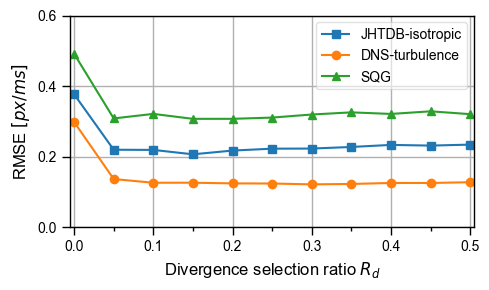

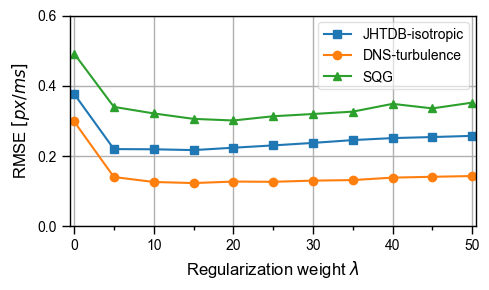

In [ ]:
with PAIRED_RESULT_PATH.open("r", encoding="utf-8") as handle:
    paired_saved = json.load(handle)
paired_metadata = paired_saved["metadata"]
if paired_metadata["status"] != "complete":
    raise RuntimeError("Finish the full training run before plotting.")
if paired_metadata["completed_training_runs"] != paired_metadata["expected_training_runs"]:
    raise ValueError("Incomplete training run count.")

paired_names = paired_metadata["flow_names"]
paired_plot_repeats = paired_metadata["num_repeats"]
paired_summary = {name: {"rd": {}, "lambda": {}} for name in paired_names}
for name in paired_names:
    for axis_name, values in (("rd", paired_metadata["rd_values"]), ("lambda", paired_metadata["lambda_values"])):
        for value in values:
            key = f"{value:.2f}" if axis_name == "rd" else str(value)
            rows = paired_saved["flows"][name][axis_name][key]
            if len(rows) != paired_plot_repeats or {row["repeat"] for row in rows} != set(range(paired_plot_repeats)):
                raise ValueError(f"Missing or duplicate repeats: {name}, {axis_name}={key}")
            values_rmse = np.asarray([row["rmse"] for row in rows], dtype=float)
            if not np.all(np.isfinite(values_rmse)):
                raise ValueError(f"Non-finite RMSE: {name}, {axis_name}={key}")
            paired_summary[name][axis_name][key] = {
                "rmse_mean": float(values_rmse.mean()),
                "rmse_std": float(values_rmse.std()),
            }
    for repeat in range(paired_plot_repeats):
        rows = [row for sweep in paired_saved["flows"][name].values()
                for values in sweep.values() for row in values if row["repeat"] == repeat]
        # Verify the actual event and initial-model fingerprints across both sweeps.
        for field in ("event_seed", "train_seed", "event_count", "events_sha256", "initial_model_sha256"):
            if len({row[field] for row in rows}) != 1:
                raise ValueError(f"Unpaired {field}: {name}, repeat={repeat}")
        for rd_key, weight_key in (("0.00", "0"), ("0.10", "10")):
            rd_row = next(row for row in paired_saved["flows"][name]["rd"][rd_key] if row["repeat"] == repeat)
            weight_row = next(row for row in paired_saved["flows"][name]["lambda"][weight_key] if row["repeat"] == repeat)
            if rd_row != weight_row:
                raise ValueError(f"Shared point mismatch: {name}, repeat={repeat}, Rd={rd_key}")
    print(f"{name}: shared baseline RMSE={paired_summary[name]['rd']['0.00']['rmse_mean']:.4f}")

paired_summary_path = PAIRED_OUTPUT_DIR / "paired-rd-lambda-summary.json"
paired_summary_path.write_text(json.dumps(paired_summary, ensure_ascii=False, indent=1, allow_nan=False))
# Use a common y range and avoid clipping any newly trained result.
paired_maximum = max(item["rmse_mean"] for flow in paired_summary.values()
              for sweep in flow.values() for item in sweep.values())
paired_upper = max(0.6, float(np.ceil((paired_maximum + 1e-6) / 0.2) * 0.2))
paired_plot_specs = [
    ("rd", paired_metadata["rd_values"], r"Divergence selection ratio $R_d$",
     (-0.005, 0.505), [0.0, 0.1, 0.2, 0.3, 0.4, 0.5], [0.05, 0.15, 0.25, 0.35, 0.45]),
    ("lambda", paired_metadata["lambda_values"], r"Regularization weight $\lambda$",
     (-0.5, 50.5), [0, 10, 20, 30, 40, 50], [5, 15, 25, 35, 45]),
]
for axis_name, x_values, xlabel, xlim, major, minor in paired_plot_specs:
    y_values = [
        [paired_summary[name][axis_name][f"{value:.2f}" if axis_name == "rd" else str(value)]["rmse_mean"]
         for value in x_values] for name in paired_names
    ]
    pdf_path = PAIRED_OUTPUT_DIR / f"{axis_name}-rmse.pdf"
    plot_curvegraph(
        x_data=x_values, y_data_list=y_values,
        legend_names_en=paired_names, legend_names_zh=paired_names,
        title_en=None, title_zh=None,
        xlabel_en=xlabel, xlabel_zh=xlabel,
        ylabel_en=r"RMSE $[px/ms]$", ylabel_zh=r"RMSE $[px/ms]$",
        ticks_size=10, legend_size=10, label_size=12,
        xlim=xlim, x_major_ticks=major, x_minor_ticks=minor,
        ylim=(0, paired_upper), y_major_ticks=np.round(np.arange(0, paired_upper + 0.1, 0.2), 2).tolist(),
        filename=str(pdf_path), figsize=(5, 3),
    )
    print(f"Saved: {pdf_path}")
